In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Customer Segmentation Analysis")
print("Libraries imported successfully!")

Customer Segmentation Analysis
Libraries imported successfully!


In [2]:
df = pd.read_csv("OnlineRetail.csv", encoding="ISO-8859-1")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [3]:
# Display dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 67.3 MB


In [4]:
# Statistical summary
df.describe()

,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,406829.000000
mean,9.552250,4.611114,15287.690570
std,218.081158,96.759853,1713.600303
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


In [5]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate Records: 5268


In [6]:
# Remove rows with missing CustomerID
df = df.dropna(subset=['CustomerID'])

# Remove duplicate records
df = df.drop_duplicates()

# Remove cancelled transactions
df = df[~df['InvoiceNo'].str.startswith('C')]

# Remove negative or zero quantity
df = df[df['Quantity'] > 0]

# Remove zero or negative prices
df = df[df['UnitPrice'] > 0]

print("Data Cleaning Completed!")
print("Cleaned Dataset Shape:", df.shape)
print("Missing CustomerID:", df['CustomerID'].isnull().sum())
print("Duplicate Records:", df.duplicated().sum())

Data Cleaning Completed!
Cleaned Dataset Shape: (392692, 8)
Missing CustomerID: 0
Duplicate Records: 0


In [7]:
# Calculate total amount
df['TotalAmount'] = df['Quantity'] * df['UnitPrice']

# Display updated dataset
df[['CustomerID', 'Quantity', 'UnitPrice', 'TotalAmount']].head()

,CustomerID,Quantity,UnitPrice,TotalAmount
0,17850.0,6,2.55,15.30
1,17850.0,6,3.39,20.34
2,17850.0,8,2.75,22.00
3,17850.0,6,3.39,20.34
4,17850.0,6,3.39,20.34


In [8]:
# Convert InvoiceDate to datetime format
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

print("Date conversion completed!")
print("First Invoice Date:", df['InvoiceDate'].min())
print("Last Invoice Date:", df['InvoiceDate'].max())
print("Data Type:", df['InvoiceDate'].dtype)

Date conversion completed!
First Invoice Date: 2010-12-01 08:26:00
Last Invoice Date: 2011-12-09 12:50:00
Data Type: datetime64[us]


In [9]:
# Set reference date
snapshot_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)

# Calculate RFM values
rfm = df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days,
    'InvoiceNo': 'nunique',
    'TotalAmount': 'sum'
})

# Rename columns
rfm.columns = ['Recency', 'Frequency', 'Monetary']

# Display RFM data
print("RFM Analysis Completed!")
print("Total Customers:", len(rfm))

rfm.head()

RFM Analysis Completed!
Total Customers: 4338


,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40


In [10]:
# Calculate RFM scores

rfm['R_Score'] = pd.qcut(
    rfm['Recency'].rank(method='first'),
    4,
    labels=[4, 3, 2, 1]
)

rfm['F_Score'] = pd.qcut(
    rfm['Frequency'].rank(method='first'),
    4,
    labels=[1, 2, 3, 4]
)

rfm['M_Score'] = pd.qcut(
    rfm['Monetary'].rank(method='first'),
    4,
    labels=[1, 2, 3, 4]
)

rfm['RFM_Score'] = (
    rfm['R_Score'].astype(str) +
    rfm['F_Score'].astype(str) +
    rfm['M_Score'].astype(str)
)

print("RFM Scoring Completed!")
rfm.head(10)

RFM Scoring Completed!


,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
CustomerID,,,,,,,
12346.0,326,1,77183.60,1,1,4,114
12347.0,2,7,4310.00,4,4,4,444
12348.0,75,4,1797.24,2,3,4,234
12349.0,19,1,1757.55,3,1,4,314
12350.0,310,1,334.40,1,1,2,112
12352.0,36,8,2506.04,3,4,4,344
12353.0,204,1,89.00,1,1,1,111
12354.0,232,1,1079.40,1,1,3,113
12355.0,214,1,459.40,1,1,2,112


In [11]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Select RFM features
features = rfm[['Recency', 'Frequency', 'Monetary']]

# Scale the data
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(features)

# Apply K-Means
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

rfm['Cluster'] = kmeans.fit_predict(rfm_scaled)

print("K-Means Clustering Completed!")
print("\nCustomer Distribution:")
print(rfm['Cluster'].value_counts().sort_index())

K-Means Clustering Completed!

Customer Distribution:
Cluster
0    3054
1    1067
2      13
3     204
Name: count, dtype: int64


In [12]:
# Analyse customer clusters

cluster_summary = rfm.groupby('Cluster').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': 'mean'
}).round(2)

print("Customer Cluster Summary:")
display(cluster_summary)

Customer Cluster Summary:


,Recency,Frequency,Monetary
Cluster,,,
0,43.70,3.68,1353.63
1,248.08,1.55,478.85
2,7.38,82.54,127187.96
3,15.50,22.33,12690.50


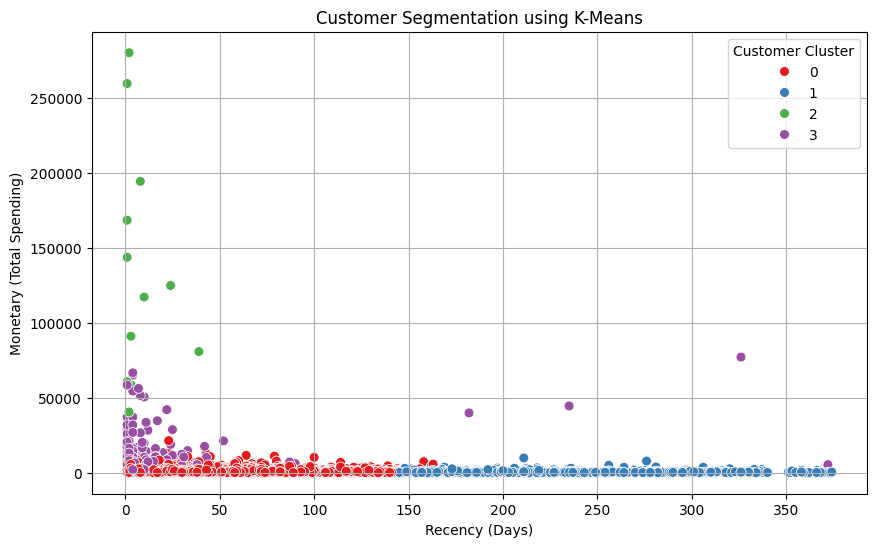

In [13]:
# Visualize customer clusters

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=rfm,
    x='Recency',
    y='Monetary',
    hue='Cluster',
    palette='Set1',
    s=50
)

plt.title('Customer Segmentation using K-Means')
plt.xlabel('Recency (Days)')
plt.ylabel('Monetary (Total Spending)')
plt.legend(title='Customer Cluster')
plt.grid(True)
plt.show()

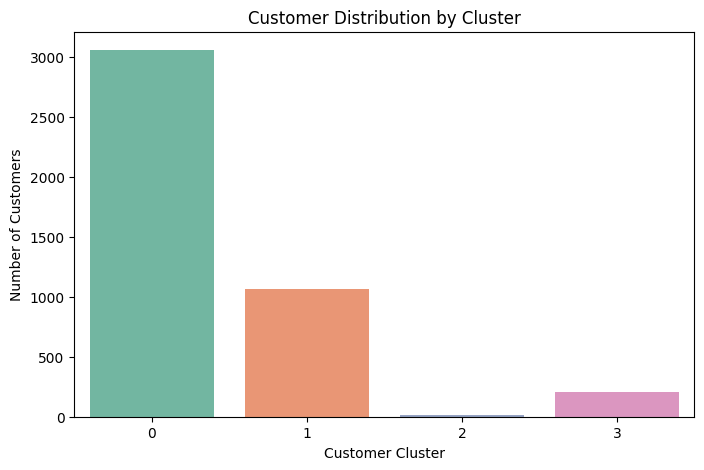

In [14]:
# Customer distribution by cluster

plt.figure(figsize=(8, 5))

sns.countplot(
    data=rfm,
    x='Cluster',
    hue='Cluster',
    palette='Set2',
    legend=False
)

plt.title('Customer Distribution by Cluster')
plt.xlabel('Customer Cluster')
plt.ylabel('Number of Customers')
plt.show()

In [15]:
# Customer segment analysis

print("CUSTOMER SEGMENT DETAILS")

for cluster in sorted(rfm['Cluster'].unique()):
    data = rfm[rfm['Cluster'] == cluster]

    print(f"\nCluster {cluster}")
    print("Number of Customers:", len(data))
    print("Average Recency:", round(data['Recency'].mean(), 2))
    print("Average Frequency:", round(data['Frequency'].mean(), 2))
    print("Average Spending:", round(data['Monetary'].mean(), 2))

CUSTOMER SEGMENT DETAILS

Cluster 0
Number of Customers: 3054
Average Recency: 43.7
Average Frequency: 3.68
Average Spending: 1353.63

Cluster 1
Number of Customers: 1067
Average Recency: 248.08
Average Frequency: 1.55
Average Spending: 478.85

Cluster 2
Number of Customers: 13
Average Recency: 7.38
Average Frequency: 82.54
Average Spending: 127187.96

Cluster 3
Number of Customers: 204
Average Recency: 15.5
Average Frequency: 22.33
Average Spending: 12690.5


In [16]:
# Calculate customer segment scores

cluster_summary['Segment_Score'] = (
    cluster_summary['Frequency'].rank(pct=True) +
    cluster_summary['Monetary'].rank(pct=True) +
    (1 - cluster_summary['Recency'].rank(pct=True))
)

# Rank clusters
cluster_summary = cluster_summary.sort_values(
    'Segment_Score', ascending=False
)

# Assign segment names
segment_names = [
    'Best Customers',
    'Loyal Customers',
    'Regular Customers',
    'Low Engagement Customers'
]

cluster_summary['Segment'] = segment_names

print("CUSTOMER SEGMENT RESULTS")
display(cluster_summary)

CUSTOMER SEGMENT RESULTS


,Recency,Frequency,Monetary,Segment_Score,Segment
Cluster,,,,,
2,7.38,82.54,127187.96,2.75,Best Customers
3,15.50,22.33,12690.50,2.00,Loyal Customers
0,43.70,3.68,1353.63,1.25,Regular Customers
1,248.08,1.55,478.85,0.50,Low Engagement Customers


In [17]:
# Final Business Insights

print("========== CUSTOMER SEGMENTATION REPORT ==========")

print("\nTotal Customers:", len(rfm))

print("\nTotal Revenue:", round(rfm['Monetary'].sum(), 2))

print("\nAverage Customer Spending:",
      round(rfm['Monetary'].mean(), 2))

print("\nNumber of Customer Segments:",
      rfm['Cluster'].nunique())

print("\nCustomer Count by Segment:")
print(rfm['Cluster'].value_counts().sort_index())

print("\nCluster Performance:")
display(cluster_summary)

========== CUSTOMER SEGMENTATION REPORT ==========

Total Customers: 4338

Total Revenue: 8887208.89

Average Customer Spending: 2048.69

Number of Customer Segments: 4

Customer Count by Segment:
Cluster
0    3054
1    1067
2      13
3     204
Name: count, dtype: int64

Cluster Performance:


,Recency,Frequency,Monetary,Segment_Score,Segment
Cluster,,,,,
2,7.38,82.54,127187.96,2.75,Best Customers
3,15.50,22.33,12690.50,2.00,Loyal Customers
0,43.70,3.68,1353.63,1.25,Regular Customers
1,248.08,1.55,478.85,0.50,Low Engagement Customers
